# 2º Trabalho de Fundamentos de IA — Etapa 6: Lógica Fuzzy e Pipeline Integrado
**Domínio:** Educação (SAEB 2021/2023 + Censo 2010) · **IComp/UFAM** · Prof. Edjard Mota

Esta etapa fecha o pipeline com um **sistema de inferência fuzzy (Mamdani)** que combina a saída da Etapa 5 (a probabilidade da Rede Bayesiana) com o nível de desempenho do município e produz uma decisão interpretável. Cobre as 7 tarefas do enunciado:

1. 2–3 **variáveis linguísticas**
2. **Funções de pertinência triangulares**
3. 3–5 **regras Se-Então** (com E/OU)
4. Sistema implementado com **scikit-fuzzy**
5. **Probabilidades Bayesianas da Etapa 5 como entrada**
6. **Decisão fuzzy × decisão "hard"** (limiar em 0,5)
7. **Interpretabilidade**: cada regra é legível por um especialista?

**Pergunta de decisão:** *qual a **prioridade de apoio pedagógico** de cada município (0–100)?* É uma decisão de gestão, diferente de "vai melhorar?", e por isso é uma saída contínua e interpretável.

> Mesmo conjunto das Etapas 1–5 (3.519 exemplos: município × dependência × localização), reconstruído e conferido contra os arquivos brutos do `Dados.zip`. A rede descreve **associações**, não efeito causal do Novo Ensino Médio.

## 0. Configuração, dados e entrada vinda da Etapa 5

In [1]:
# scikit-fuzzy é exigido pelo enunciado (Tarefa 4). No Colab: instala se faltar.
import importlib.util, subprocess, sys
if importlib.util.find_spec('skfuzzy') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'scikit-fuzzy'])

In [2]:
import io, gzip, base64, warnings, itertools
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
pd.set_option('display.width', 160, 'display.max_columns', 30)

# Conjunto das Etapas 1-5 (SAEB 2021 + SAEB 2023 + IDHM_R do Censo 2010), embutido para dispensar uploads.
EMBUTIDO = "..."
df = pd.read_csv(io.StringIO(gzip.decompress(base64.b64decode(EMBUTIDO)).decode()))

# As mesmas 5 variáveis binárias da Etapa 5 (1 = verdadeiro)
d = pd.DataFrame({
    'R': (df.CO_UF // 10).isin([1, 2]).astype(int),                 # R: Norte/Nordeste
    'I': (df.IDHM_R < 0.6).astype(int),                              # I: IDHM-Renda baixo
    'U': (df.LOCALIZACAO == 'Rural').astype(int),                    # U: rural
    'B': (df.MEDIA_12_MT_2021 < 265).astype(int),                    # B: média 2021 baixa
    'M': (df.MEDIA_12_MT_2023 > df.MEDIA_12_MT_2021).astype(int),    # M: melhorou (alvo)
})
nota = df.MEDIA_12_MT_2021.values; groups = df.CO_MUNICIPIO.values
print(f'N = {len(d)} | P(melhora) = {d.M.mean():.3f} | média SAEB 2021: {nota.mean():.1f} ± {nota.std():.1f} (min {nota.min():.0f}, máx {nota.max():.0f})')

N = 3519 | P(melhora) = 0.631 | média SAEB 2021: 265.1 ± 20.1 (min 188, máx 400)


### 0.1 Funções do zero
`BayesNet` é a rede da Etapa 5 (mesmo código de `bn.py`), usada para obter a probabilidade que entra no sistema fuzzy. As funções fuzzy são as de `fuzzy.py`: o sistema com **scikit-fuzzy** e uma versão **manual** (numpy) do mesmo Mamdani, só para conferir e para rodar rápido em milhares de municípios.

In [3]:
import itertools
import numpy as np
import pandas as pd

# --- Rede Bayesiana da Etapa 5 (CPTs com Laplace + inferência por enumeração) ---
class BayesNet:
    """parents: dict no -> lista de pais (DAG). Todas as variaveis sao binarias (0/1).
    cpt[no][(v_pai1, v_pai2, ...)] = [P(no=0 | pais), P(no=1 | pais)]."""

    def __init__(self, parents):
        self.parents = {n: list(p) for n, p in parents.items()}
        self.nodes = list(parents)
        self.cpt = {}

    # --- Tarefa 2: estimar CPTs a partir dos dados (MLE com suavizacao de Laplace = MAP com prior de Dirichlet)
    def fit(self, data, alpha=1.0):
        for n in self.nodes:
            pa = self.parents[n]; self.cpt[n] = {}
            for combo in itertools.product([0, 1], repeat=len(pa)):
                m = np.ones(len(data), bool)
                for p, v in zip(pa, combo): m &= (data[p].values == v)
                k1 = float(data[n].values[m].sum()); tot = float(m.sum())
                p1 = (k1 + alpha) / (tot + 2 * alpha)
                self.cpt[n][combo] = np.array([1 - p1, p1])
        return self

    # --- regra da cadeia: P(x1..xn) = prod_i P(xi | pais(xi))
    def joint(self, a):
        p = 1.0
        for n in self.nodes:
            p *= self.cpt[n][tuple(a[q] for q in self.parents[n])][a[n]]
        return p

    # --- Tarefa 3: inferencia por enumeracao
    def prob_evidence(self, evidence):
        """P(evidence) = soma da conjunta sobre todas as variaveis ocultas."""
        hidden = [n for n in self.nodes if n not in evidence]
        total = 0.0
        for vals in itertools.product([0, 1], repeat=len(hidden)):
            a = dict(evidence); a.update(zip(hidden, vals)); total += self.joint(a)
        return total

    def query(self, var, evidence=None):
        """P(var | evidence) por enumeracao: soma a conjunta sobre as ocultas e normaliza."""
        evidence = dict(evidence or {}); hidden = [n for n in self.nodes if n != var and n not in evidence]
        dist = np.zeros(2)
        for x in (0, 1):
            for vals in itertools.product([0, 1], repeat=len(hidden)):
                a = dict(evidence); a[var] = x; a.update(zip(hidden, vals)); dist[x] += self.joint(a)
        return dist / dist.sum()

    def n_params(self):
        """Parametros livres: 1 por linha de cada CPT (binaria): sum_i 2^|pais(i)|."""
        return sum(2 ** len(p) for p in self.parents.values())


def n_params_conjunta(n_vars):
    return 2 ** n_vars - 1

In [4]:
# --- Sistema fuzzy: universos, funções de pertinência, scikit-fuzzy e Mamdani manual ---
import numpy as np


NOTA_LO, NOTA_HI = 230.0, 300.0            # nota SAEB 2021 e' "cortada" nesta faixa antes de entrar no sistema
U_RISCO = np.arange(0, 1.0001, 0.01)
U_NOTA = np.arange(NOTA_LO, NOTA_HI + 0.001, 1.0)
U_PRIOR = np.arange(0, 100.001, 1.0)

MF_RISCO = {'baixo': [0, 0, 1], 'alto': [0, 1, 1]}          # complementares: se cruzam em 0,5 (o limiar rigido)
MF_NOTA = {'baixa': [NOTA_LO, NOTA_LO, NOTA_HI], 'alta': [NOTA_LO, NOTA_HI, NOTA_HI]}
MF_PRIOR = {'baixa': [0, 0, 40], 'media': [20, 50, 80], 'alta': [60, 100, 100]}


def trimf(x, abc):
    """Pertinencia triangular [a, b, c] (a=b ou b=c dao 'rampas')."""
    x = np.asarray(x, float); a, b, c = abc
    y = np.zeros_like(x)
    if b > a: y = np.where((x > a) & (x < b), (x - a) / (b - a), y)
    if c > b: y = np.where((x > b) & (x < c), (c - x) / (c - b), y)
    y = np.where(x == b, 1.0, y)
    if a == b: y = np.where(x <= a, 1.0, y)
    if b == c: y = np.where(x >= c, 1.0, y)
    return y

def build_sistema():
    import skfuzzy as fuzz
    from skfuzzy import control as ctrl
    risco = ctrl.Antecedent(U_RISCO, 'risco'); nota = ctrl.Antecedent(U_NOTA, 'nota'); prior = ctrl.Consequent(U_PRIOR, 'prioridade')
    for k, v in MF_RISCO.items(): risco[k] = fuzz.trimf(risco.universe, v)
    for k, v in MF_NOTA.items(): nota[k] = fuzz.trimf(nota.universe, v)
    for k, v in MF_PRIOR.items(): prior[k] = fuzz.trimf(prior.universe, v)
    regras = [
        ctrl.Rule(nota['baixa'], prior['alta']),                       # R1: nível baixo => prioridade alta
        ctrl.Rule(nota['alta'] & risco['alto'], prior['media']),       # R2: nível alto, mas queda provável: monitorar
        ctrl.Rule(nota['alta'] & risco['baixo'], prior['baixa']),      # R3: nível alto e sem risco relevante
    ]
    return ctrl.ControlSystem(regras), (risco, nota, prior), regras


def prioridade_skfuzzy(sistema, risco, nota):
    from skfuzzy import control as ctrl
    sim = ctrl.ControlSystemSimulation(sistema)
    sim.input['risco'] = float(np.clip(risco, 0, 1)); sim.input['nota'] = float(np.clip(nota, NOTA_LO, NOTA_HI))
    sim.compute(); return float(sim.output['prioridade'])

def mamdani_manual(risco, nota):
    """min = E, max = OU, implicacao por min (corte), agregacao por max, defuzzificacao por centroide."""
    r = np.clip(np.atleast_1d(risco).astype(float), 0, 1); n = np.clip(np.atleast_1d(nota).astype(float), NOTA_LO, NOTA_HI)
    r_b, r_a = trimf(r, MF_RISCO['baixo']), trimf(r, MF_RISCO['alto'])
    n_b, n_a = trimf(n, MF_NOTA['baixa']), trimf(n, MF_NOTA['alta'])
    ativ = {'R1': n_b, 'R2': np.minimum(n_a, r_a), 'R3': np.minimum(n_a, r_b)}
    saida = {'alta': ativ['R1'], 'media': ativ['R2'], 'baixa': ativ['R3']}
    agreg = np.zeros((len(r), len(U_PRIOR)))
    for k, a in saida.items():
        agreg = np.maximum(agreg, np.minimum(a[:, None], trimf(U_PRIOR, MF_PRIOR[k])[None, :]))
    trap = np.trapezoid if hasattr(np, 'trapezoid') else np.trapz          # centroide por integração trapezoidal (como o scikit-fuzzy)
    return trap(agreg * U_PRIOR, U_PRIOR, axis=1) / trap(agreg, U_PRIOR, axis=1), ativ

## 1. A entrada vinda da Etapa 5 (Tarefa 5)
Usamos o **mesmo DAG** da Etapa 5 (`R→I, R→U, R→B, I→B, U→B, B→M, I→M`) e, para cada município, a inferência por enumeração
$$\text{risco}=1-P(M=1\mid R,I,U,B)\qquad(\text{risco de **não** melhorar})$$
As CPTs de cada partição são estimadas **só com o treino** (mesmas 5 partições agrupadas por município das Etapas 1, 2, 4 e 5) e o risco de cada município vem da partição em que ele é **teste**, para não vazar o desfecho.

In [5]:
PAIS = {'R': [], 'I': ['R'], 'U': ['R'], 'B': ['R', 'I', 'U'], 'M': ['B', 'I']}

def kfold_por_grupo(y, grupos, k=5, seed=SEED):
    # 5-fold agrupado por município (mesma função das Etapas 1, 2, 4 e 5)
    rng = np.random.RandomState(seed); y = np.asarray(y); grupos = np.asarray(grupos)
    ids = pd.unique(grupos); rng.shuffle(ids)
    info = pd.DataFrame({'g': grupos, 'y': y}).groupby('g').y.agg(['size', 'sum']).loc[ids]
    info = info.sort_values('size', ascending=False, kind='stable')
    tam, pos, dest, p1 = np.zeros(k), np.zeros(k), {}, y.mean()
    for g, (n, s_) in info.iterrows():
        f = min(range(k), key=lambda j: (tam[j], pos[j] - p1 * tam[j]))
        dest[g] = f; tam[f] += n; pos[f] += s_
    fold = np.array([dest[g] for g in grupos])
    return [(np.where(fold != j)[0], np.where(fold == j)[0]) for j in range(k)]

COMBOS = list(itertools.product([0, 1], repeat=4))                      # (R, I, U, B)
IDX = (d[['R', 'I', 'U', 'B']].values * np.array([8, 4, 2, 1])).sum(1)  # índice 0..15 da combinação de cada linha
def tabela_risco(rd):                                                   # risco para as 16 combinações, por enumeração
    return np.array([1 - rd.query('M', dict(zip('RIUB', c)))[1] for c in COMBOS])

folds = kfold_por_grupo(d.M.values, groups)
print('municípios disjuntos entre treino e teste:', all(set(groups[a]).isdisjoint(groups[b]) for a, b in folds))
risco = np.zeros(len(d))
for tr, te in folds:
    risco[te] = tabela_risco(BayesNet(PAIS).fit(d.iloc[tr]))[IDX[te]]
risco0 = tabela_risco(BayesNet(PAIS).fit(d))[IDX]                       # rede ajustada em todos os dados (para tabelas e bootstrap)

g = pd.DataFrame({'B': d.B, 'I': d.I, 'risco (fora-da-amostra)': risco, 'risco (rede completa)': risco0, 'nota': nota})
print(g.groupby(['B', 'I']).agg(n=('nota', 'size'), risco_min=('risco (fora-da-amostra)', 'min'), risco_max=('risco (fora-da-amostra)', 'max'),
                                risco_rede_completa=('risco (rede completa)', 'mean'), nota_media=('nota', 'mean')).round(3).to_string())

municípios disjuntos entre treino e teste: True
        n  risco_min  risco_max  risco_rede_completa  nota_media
B I                                                             
0 0  1530      0.573      0.587                0.582     280.445
  1   289      0.469      0.523                0.502     278.668
1 0   840      0.190      0.201                0.196     253.821
  1   860      0.107      0.125                0.115     244.202


**Leitura:** o risco de não melhorar só assume **4 valores** na rede completa (depende de `B` e `I`, os pais de `M`), entre ≈ 0,12 e 0,58. Em quem partiu de média **baixa** (B=1) ele é pequeno (0,12–0,20) e em quem partiu **alta** (B=0) é grande (0,50–0,58): é a regressão à média das Etapas 1–3. Repare em B=0, I=1: o risco fica **colado em 0,50** (0,502 na rede completa; varia de 0,47 a 0,52 entre partições). Um limiar rígido em 0,5 cai exatamente aí, e esse é o caso que o fuzzy deve tratar melhor.

Também importa: **risco e nota são muito correlacionados** (correlação ≈ 0,8): quem tem risco alto é quem já tinha nota alta. Isso orienta as regras abaixo.

## 2. Variáveis linguísticas e funções de pertinência (Tarefas 1 e 2)
Três variáveis (2 entradas, 1 saída), todas com funções de pertinência **triangulares**:

| Variável | Papel | Universo | Conjuntos (triângulos `[a, b, c]`) | De onde vem |
|---|---|---|---|---|
| `risco` | entrada | 0–1 | baixo `[0, 0, 1]` · alto `[0, 1, 1]` | Rede Bayesiana (Etapa 5) |
| `nota` | entrada | 230–300 | baixa `[230, 230, 300]` · alta `[230, 300, 300]` | média SAEB 2021 (nota contínua; a rede só a via em 2 faixas) |
| `prioridade` | saída | 0–100 | baixa `[0, 0, 40]` · média `[20, 50, 80]` · alta `[60, 100, 100]` | decisão de gestão |

Escolhas e justificativas:
- **`risco`:** dois conjuntos **complementares** (somam 1) que se cruzam exatamente em **0,5**: ali o risco é "meio baixo, meio alto". Assim o limiar rígido da Tarefa 6 vira uma zona de transição em vez de um degrau. (Uma primeira versão com 3 conjuntos e a regra "risco baixo OU médio" criava uma queda artificial na superfície, porque o máximo de dois triângulos sempre afunda no cruzamento; por isso foi simplificada.)
- **`nota`:** só 2 conjuntos, que se somam a 1 e **se cruzam em 265**, o ponto de corte `B` da Etapa 3 (e o centro das faixas 250/265/280 da Etapa 1). Valores abaixo de 230 ou acima de 300 (≈ 5% de cada cauda) são **cortados** nesses limites antes de entrar no sistema: "claramente baixa" e "claramente alta".
- **`prioridade`:** 3 níveis com sobreposição, como no pseudocódigo do enunciado.

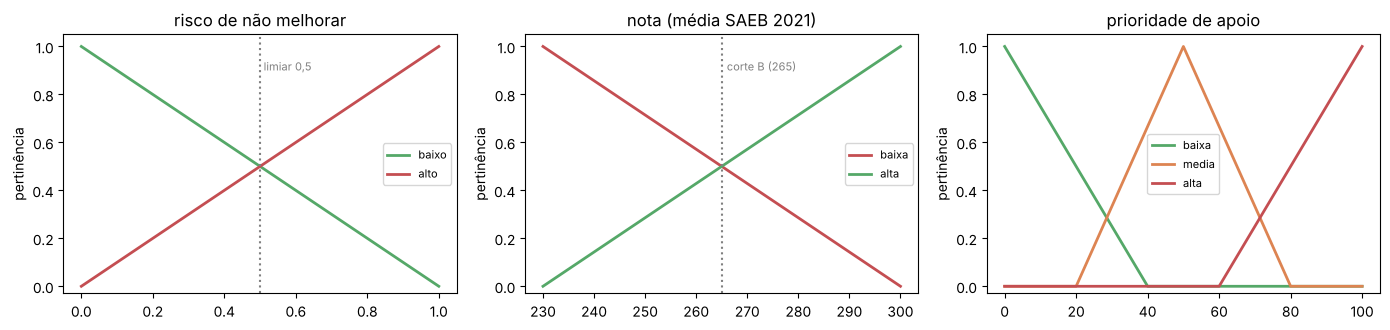

In [6]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.4))
for ax, (nome, uni, mfs, cores) in zip(axs, [('risco de não melhorar', U_RISCO, MF_RISCO, ['#55a868', '#c44e52']),
                                             ('nota (média SAEB 2021)', U_NOTA, MF_NOTA, ['#c44e52', '#55a868']),
                                             ('prioridade de apoio', U_PRIOR, MF_PRIOR, ['#55a868', '#dd8452', '#c44e52'])]):
    for (k, v), c in zip(mfs.items(), cores): ax.plot(uni, trimf(uni, v), lw=2, c=c, label=k)
    ax.set_title(nome); ax.set_ylim(-.03, 1.05); ax.legend(fontsize=8); ax.set_ylabel('pertinência')
axs[0].axvline(0.5, ls=':', c='gray'); axs[0].text(0.51, .9, 'limiar 0,5', fontsize=8, color='gray')
axs[1].axvline(265, ls=':', c='gray'); axs[1].text(266, .9, 'corte B (265)', fontsize=8, color='gray')
plt.tight_layout(); plt.show()

## 3. Regras Se-Então (Tarefa 3)
Três regras, escritas em linguagem de gestão. A lógica vem das etapas anteriores: **o nível de desempenho vem primeiro** (nota baixa pede apoio mesmo que a rede preveja recuperação, porque a "melhora" de quem partiu de baixo é em boa parte regressão à média e não fecha a lacuna). **O risco entra para refinar** os municípios de nível alto.

| # | Regra | Operadores |
|---|---|---|
| **R1** | **SE** a nota é *baixa* **ENTÃO** a prioridade é *alta* | — |
| **R2** | **SE** a nota é *alta* **E** o risco de não melhorar é *alto* **ENTÃO** a prioridade é *média* (queda provável a partir de um patamar alto: monitorar) | E |
| **R3** | **SE** a nota é *alta* **E** o risco é *baixo* **ENTÃO** a prioridade é *baixa* | E |

Operadores (Mamdani): **E = mínimo** (o **OU** do scikit-fuzzy, máximo, está disponível, mas nenhuma regra o usa: o único OU natural, "risco baixo OU médio", gerava um degrau artificial na saída), implicação por **corte (mínimo)**, agregação por **máximo** e defuzzificação pelo **centroide**.

## 4. Sistema Mamdani com scikit-fuzzy (Tarefa 4)

In [7]:
sistema, (a_risco, a_nota, a_prior), regras = build_sistema()
for i, r in enumerate(regras, 1): print(f'R{i}:', r)

# Exemplo do pseudocódigo do enunciado (Listing 4): uma entrada, uma saída
print('\nExemplos de entrada → prioridade (scikit-fuzzy):')
for rk, nt in [(0.15, 245), (0.15, 285), (0.50, 275), (0.58, 285), (0.50, 265), (0.30, 265)]:
    print(f'  risco = {rk:.2f}, nota = {nt:>3} → prioridade = {prioridade_skfuzzy(sistema, rk, nt):5.1f}')

# Conferência: o Mamdani manual (numpy) deve reproduzir o scikit-fuzzy
rng = np.random.RandomState(SEED); pts = np.column_stack([rng.rand(400), rng.uniform(210, 320, 400)])
sk = np.array([prioridade_skfuzzy(sistema, r, n) for r, n in pts]); man, _ = mamdani_manual(pts[:, 0], pts[:, 1])
print(f'\nscikit-fuzzy × Mamdani manual em 400 pontos aleatórios: mediana |dif| = {np.median(np.abs(sk - man)):.4f} | máx |dif| = {np.abs(sk - man).max():.4f} (escala 0–100)')

R1: IF nota[baixa] THEN prioridade[alta]
	AND aggregation function : fmin
	OR aggregation function  : fmax
R2: IF nota[alta] AND risco[alto] THEN prioridade[media]
	AND aggregation function : fmin
	OR aggregation function  : fmax
R3: IF nota[alta] AND risco[baixo] THEN prioridade[baixa]
	AND aggregation function : fmin
	OR aggregation function  : fmax

Exemplos de entrada → prioridade (scikit-fuzzy):
  risco = 0.15, nota = 245 → prioridade =  64.5
  risco = 0.15, nota = 285 → prioridade =  35.5
  risco = 0.50, nota = 275 → prioridade =  47.1
  risco = 0.58, nota = 285 → prioridade =  45.0
  risco = 0.50, nota = 265 → prioridade =  50.0
  risco = 0.30, nota = 265 → prioridade =  50.0



scikit-fuzzy × Mamdani manual em 400 pontos aleatórios: mediana |dif| = 0.0028 | máx |dif| = 0.0190 (escala 0–100)


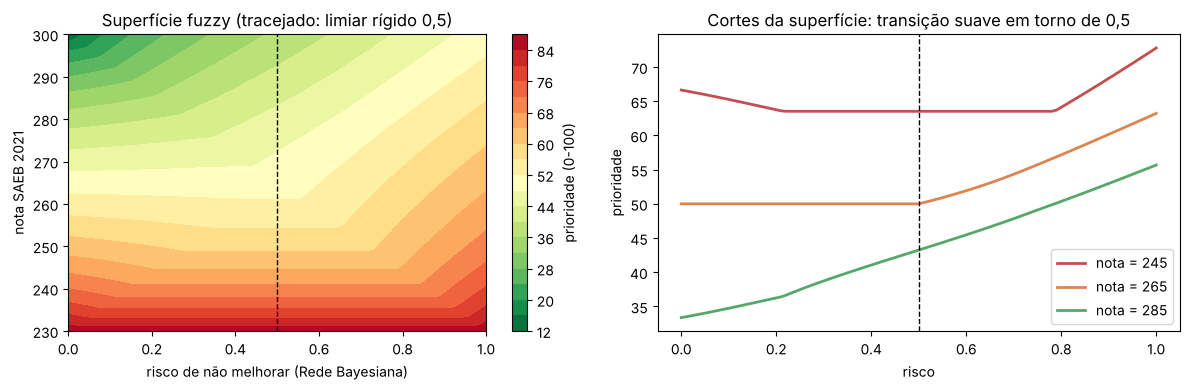

In [8]:
# Superfície de decisão: prioridade em função de (risco, nota)
gr, gn = np.meshgrid(np.linspace(0, 1, 101), np.linspace(NOTA_LO, NOTA_HI, 71))
Z, _ = mamdani_manual(gr.ravel(), gn.ravel()); Z = Z.reshape(gr.shape)
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
im = axs[0].contourf(gr, gn, Z, levels=20, cmap='RdYlGn_r'); plt.colorbar(im, ax=axs[0], label='prioridade (0-100)')
axs[0].axvline(0.5, c='k', ls='--', lw=1); axs[0].set_xlabel('risco de não melhorar (Rede Bayesiana)'); axs[0].set_ylabel('nota SAEB 2021')
axs[0].set_title('Superfície fuzzy (tracejado: limiar rígido 0,5)')
for nt, c in [(245, '#c44e52'), (265, '#dd8452'), (285, '#55a868')]:
    zz, _ = mamdani_manual(np.linspace(0, 1, 101), np.full(101, nt)); axs[1].plot(np.linspace(0, 1, 101), zz, c=c, lw=2, label=f'nota = {nt}')
axs[1].axvline(0.5, c='k', ls='--', lw=1); axs[1].set_xlabel('risco'); axs[1].set_ylabel('prioridade'); axs[1].legend(); axs[1].set_title('Cortes da superfície: transição suave em torno de 0,5')
plt.tight_layout(); plt.show()

## 5. Aplicação aos municípios (Tarefa 5)
Alimentamos o sistema com o `risco` da Rede Bayesiana (Seção 1, fora-da-amostra) e a `nota` de cada município. A **decisão hard** de referência é a do enunciado: limiar de 0,5 na probabilidade (`intervir` se $P(\text{melhora})<0{,}5$, isto é, `risco > 0,5`).

Distribuição da prioridade fuzzy: {'count': 3519.0, 'mean': 54.3, 'std': 11.2, 'min': 35.9, '25%': 47.5, '50%': 50.8, '75%': 59.1, 'max': 86.7}

Por grupo da rede (B, I):
        n  nota_media  risco_medio  hard_pct_intervir  prior_media  prior_dp
B I                                                                         
0 0  1530     280.445        0.582              1.000       46.791     3.816
  1   289     278.668        0.502              0.619       45.849     4.107
1 0   840     253.821        0.196              0.000       57.969     7.696
  1   860     244.202        0.116              0.000       66.836    11.473

Correlação prioridade × nota = -0.93 | prioridade × risco = -0.73


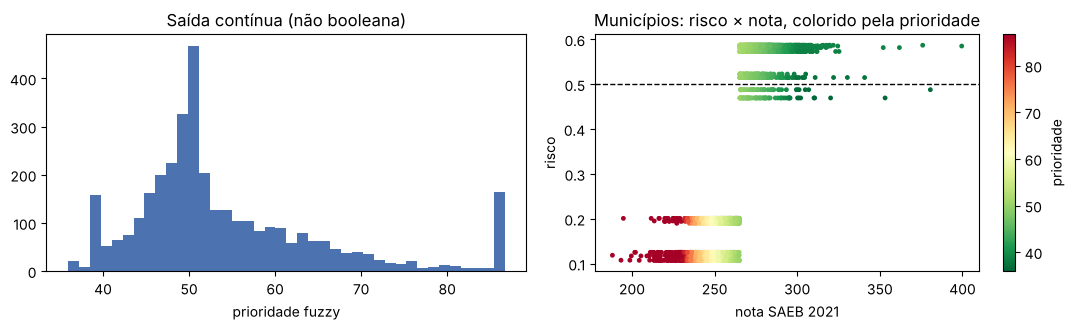

In [9]:
prior, ativ = mamdani_manual(risco, nota)
hard = (risco > 0.5).astype(int)
res = pd.DataFrame({'B': d.B, 'I': d.I, 'nota': nota, 'risco': risco, 'hard (risco>0,5)': hard, 'prioridade fuzzy': prior})
print('Distribuição da prioridade fuzzy:', pd.Series(prior).describe().round(1).to_dict())
print('\nPor grupo da rede (B, I):')
print(res.groupby(['B', 'I']).agg(n=('nota', 'size'), nota_media=('nota', 'mean'), risco_medio=('risco', 'mean'),
                                  hard_pct_intervir=('hard (risco>0,5)', 'mean'), prior_media=('prioridade fuzzy', 'mean'), prior_dp=('prioridade fuzzy', 'std')).round(3).to_string())
print(f"\nCorrelação prioridade × nota = {np.corrcoef(prior, nota)[0, 1]:.2f} | prioridade × risco = {np.corrcoef(prior, risco)[0, 1]:.2f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(prior, bins=40, color='#4c72b0'); ax[0].set_xlabel('prioridade fuzzy'); ax[0].set_title('Saída contínua (não booleana)')
sc = ax[1].scatter(nota, risco, c=prior, s=6, cmap='RdYlGn_r'); plt.colorbar(sc, ax=ax[1], label='prioridade'); ax[1].axhline(.5, c='k', ls='--', lw=1)
ax[1].set_xlabel('nota SAEB 2021'); ax[1].set_ylabel('risco'); ax[1].set_title('Municípios: risco × nota, colorido pela prioridade'); plt.tight_layout(); plt.show()

## 6. Decisão fuzzy × decisão hard (Tarefa 6)
Comparamos em três frentes: **(a)** o que acontece na fronteira, **(b)** estabilidade quando as probabilidades são estimadas com dados diferentes (dados ruidosos) e **(c)** alinhamento com o que realmente aconteceu depois (2023).

### 6.1 Na fronteira

In [10]:
g0 = pd.DataFrame({'B': d.B, 'I': d.I, 'risco0': risco0}).drop_duplicates().groupby(['B', 'I']).risco0.mean()
lin = []
for (b_, i_), rk in g0.items():
    lin.append({'grupo (B,I)': f'B={b_}, I={i_}', 'risco (rede completa)': rk, 'decisão hard': 'INTERVIR' if rk > 0.5 else 'não intervir',
                **{f'fuzzy, nota={nt}': mamdani_manual(rk, nt)[0][0] for nt in (255, 265, 275, 290)}})
print(pd.DataFrame(lin).round(3).to_string(index=False))
print('\nTransição ao varrer o risco em torno do limiar (nota = 280):')
for rk in [0.40, 0.45, 0.49, 0.50, 0.51, 0.55, 0.60]:
    print(f'  risco = {rk:.2f} → hard: {"INTERVIR" if rk > 0.5 else "não":<8} | fuzzy: {mamdani_manual(rk, 280)[0][0]:5.1f}')

grupo (B,I)  risco (rede completa) decisão hard  fuzzy, nota=255  fuzzy, nota=265  fuzzy, nota=275  fuzzy, nota=290
   B=0, I=0                  0.582     INTERVIR           55.528            51.55           48.726           43.067
   B=0, I=1                  0.502     INTERVIR           55.528            50.03           47.142           41.175
   B=1, I=0                  0.196 não intervir           56.555            50.00           43.445           32.865
   B=1, I=1                  0.115 não intervir           57.093            50.00           42.907           30.263

Transição ao varrer o risco em torno do limiar (nota = 280):
  risco = 0.40 → hard: não      | fuzzy:  43.3
  risco = 0.45 → hard: não      | fuzzy:  44.3
  risco = 0.49 → hard: não      | fuzzy:  45.1
  risco = 0.50 → hard: não      | fuzzy:  45.3
  risco = 0.51 → hard: INTERVIR | fuzzy:  45.5
  risco = 0.55 → hard: INTERVIR | fuzzy:  46.3
  risco = 0.60 → hard: INTERVIR | fuzzy:  47.4


**Leitura:** o grupo B=0, I=1 tem risco ≈ 0,502: o limiar rígido diz **INTERVIR** por uma diferença de 0,002 e trata esse grupo igual ao de risco 0,58, enquanto um risco de 0,499 receberia a decisão oposta. No fuzzy a prioridade varia de forma **contínua**: ao varrer o risco de 0,49 a 0,51, a saída muda de 45,1 para 45,5 (0,4 ponto), e não de "não" para "sim". A transição "nota baixa → alta" também é gradual em torno de 265. Um ponto de honestidade: o risco **pesa pouco** na saída (com nota 280, varrer o risco de 0,40 a 0,60 move a prioridade só de 43 a 47); quem manda é a nota.

### 6.2 Estabilidade quando os dados mudam (bootstrap por município)
Se re-estimarmos a rede em 200 amostras *bootstrap* (municípios sorteados com reposição), as probabilidades mudam um pouco. Medimos quantos municípios **mudam de decisão** com o limiar rígido e o **quanto** muda a prioridade fuzzy (escala 0–100). Cuidado ao interpretar: a estabilidade do fuzzy vem em boa parte de o risco pesar pouco na saída (a nota, que não varia entre as amostras, domina); mesmo assim, é a propriedade que importa quando a probabilidade é incerta.

200 reamostragens. Municípios que MUDAM de decisão (hard, limiar 0,5): média = 3.7% (máx 8.2%)
Fuzzy: variação média da prioridade = 0.16 pontos | municípios com |Δ| > 5 pontos: 0.0% | com |Δ| > 20 pontos: 0.0%
Hard: cada mudança de decisão é um salto de 100 pontos na escala 0-100 (0 ↔ 100).

Grupo B=0, I=1: risco bootstrap = 0.501 ± 0.030; fração das amostras com risco > 0,5 (decisão INTERVIR) = 55%


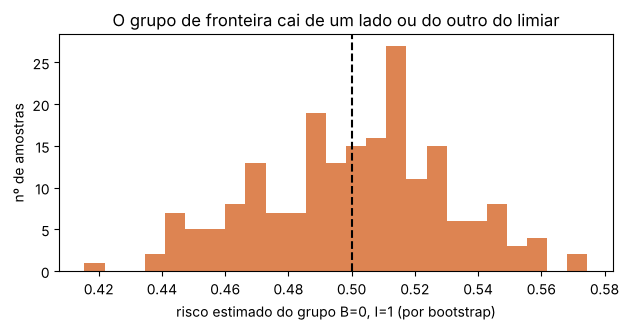

In [11]:
rng = np.random.RandomState(SEED); ids = pd.unique(groups); idx_por_grupo = pd.Series(np.arange(len(d))).groupby(groups).apply(np.array)
hard_ref = (risco0 > .5).astype(int); prior_ref, _ = mamdani_manual(risco0, nota)       # decisão com a rede ajustada em todos os dados
frontiera = (d.B.values == 0) & (d.I.values == 1)                                       # grupo de fronteira (risco ≈ 0,5)
BOOT = 200; flips_hard, dpri_mean, dpri_gt5, dpri_gt20, risco_g01 = [], [], [], [], []
for _ in range(BOOT):
    amostra = np.concatenate(idx_por_grupo.loc[rng.choice(ids, len(ids), replace=True)].values)     # sorteia municípios inteiros
    r_b = tabela_risco(BayesNet(PAIS).fit(d.iloc[amostra]))[IDX]                                     # re-estima a rede e o risco de todos
    p_b, _ = mamdani_manual(r_b, nota)
    flips_hard.append(((r_b > .5).astype(int) != hard_ref).mean())
    dp = np.abs(p_b - prior_ref); dpri_mean.append(dp.mean()); dpri_gt5.append((dp > 5).mean()); dpri_gt20.append((dp > 20).mean())
    risco_g01.append(r_b[frontiera].mean())
risco_g01 = np.array(risco_g01)
print(f'{BOOT} reamostragens. Municípios que MUDAM de decisão (hard, limiar 0,5): média = {np.mean(flips_hard):.1%} (máx {np.max(flips_hard):.1%})')
print(f'Fuzzy: variação média da prioridade = {np.mean(dpri_mean):.2f} pontos | municípios com |Δ| > 5 pontos: {np.mean(dpri_gt5):.1%} | com |Δ| > 20 pontos: {np.mean(dpri_gt20):.1%}')
print(f'Hard: cada mudança de decisão é um salto de 100 pontos na escala 0-100 (0 ↔ 100).')
print(f'\nGrupo B=0, I=1: risco bootstrap = {risco_g01.mean():.3f} ± {risco_g01.std():.3f}; fração das amostras com risco > 0,5 (decisão INTERVIR) = {(risco_g01 > .5).mean():.0%}')
fig, ax = plt.subplots(figsize=(6.4, 3.4)); ax.hist(risco_g01, bins=25, color='#dd8452'); ax.axvline(.5, c='k', ls='--'); ax.set_xlabel('risco estimado do grupo B=0, I=1 (por bootstrap)'); ax.set_ylabel('nº de amostras')
ax.set_title('O grupo de fronteira cai de um lado ou do outro do limiar'); plt.tight_layout(); plt.show()

### 6.3 Alinhamento com o que aconteceu (fora-da-amostra)
Dois desfechos reais medem coisas diferentes:
- **`ficou baixo em 2023`** (média SAEB 2023 < 265): o município **realmente precisava de apoio**. É o desfecho que a "prioridade de apoio" pretende captar.
- **`não melhorou`** (`M=0`): é o alvo da Rede Bayesiana, aquilo que o limiar de 0,5 sobre a probabilidade pretende prever.

Para comparar com a mesma "verba", o fuzzy seleciona os **mesmos 48,6% de municípios** que o limiar rígido marca (os de maior prioridade). Como referência, mostramos também a **nota 2021 sozinha** (sem Rede e sem regras).

In [12]:
from sklearn.metrics import roc_auc_score
desfechos = {'ficou baixo em 2023 (média 2023 < 265)': (df.MEDIA_12_MT_2023 < 265).values.astype(int), 'não melhorou (M=0)': 1 - d.M.values}
k = int(hard.sum()); topk = lambda s: np.isin(np.arange(len(s)), np.argsort(-s, kind='stable')[:k]).astype(int)
decisoes = {'Hard: risco > 0,5 (Rede)': (hard, risco), 'Fuzzy (mesma cobertura)': (topk(prior), prior), 'Referência: só a nota 2021 (mesma cobertura)': (topk(-nota), -nota)}
linhas = []
for dn, y_ in desfechos.items():
    for nome, (sel, score) in decisoes.items():
        tp = int((sel & y_).sum())
        linhas.append({'desfecho': dn, 'decisão': nome, 'marcados': int(sel.sum()), 'precisão': tp / sel.sum(), 'recall': tp / y_.sum(), 'AUC do escore': roc_auc_score(y_, score)})
tab_c = pd.DataFrame(linhas); print({dn: round(float(y_.mean()), 3) for dn, y_ in desfechos.items()}, '← prevalência de cada desfecho\n')
print(tab_c.round(3).to_string(index=False))

{'ficou baixo em 2023 (média 2023 < 265)': 0.415, 'não melhorou (M=0)': 0.369} ← prevalência de cada desfecho

                              desfecho                                      decisão  marcados  precisão  recall  AUC do escore
ficou baixo em 2023 (média 2023 < 265)                     Hard: risco > 0,5 (Rede)      1709     0.138   0.161          0.178
ficou baixo em 2023 (média 2023 < 265)                      Fuzzy (mesma cobertura)      1709     0.700   0.820          0.880
ficou baixo em 2023 (média 2023 < 265) Referência: só a nota 2021 (mesma cobertura)      1709     0.709   0.829          0.881
                    não melhorou (M=0)                     Hard: risco > 0,5 (Rede)      1709     0.568   0.747          0.731
                    não melhorou (M=0)                      Fuzzy (mesma cobertura)      1709     0.155   0.204          0.218
                    não melhorou (M=0) Referência: só a nota 2021 (mesma cobertura)      1709     0.154   0.203          0.215


**Leitura:** as duas decisões respondem a perguntas **diferentes**, e isso aparece nos números. Para achar municípios que **terminam com média baixa** em 2023, o limiar de 0,5 sobre a probabilidade da Rede é **pior que sortear** (precisão 14% contra 41,5% de prevalência; AUC 0,18): ele marca justamente os municípios que já partiam de nota alta e têm "risco" de cair, por regressão à média. O fuzzy, que põe o **nível** na frente (R1) e usa o risco só para refinar, acerta bem mais (precisão 70%, AUC 0,88). Para prever **"não melhorou"** acontece o inverso: o limiar da Rede (treinada para isso) acerta 57% dos marcados contra 37% de prevalência, e o fuzzy fica **abaixo do acaso** (16%), porque prioriza quem tem nota baixa, justamente quem mais melhora.

Atenção a duas coisas honestas: (i) o fuzzy aqui é **praticamente idêntico à nota sozinha** como escore de necessidade (AUC 0,880 contra 0,881): como risco e nota são muito correlacionados, a Rede quase não muda a ordenação. O que a combinação dá é **interpretabilidade e suavidade**, não mais acurácia; (ii) as regras foram escritas por lógica de domínio, mas uma primeira versão (que tratava nota baixa e nota alta de forma simétrica) deu prioridades invertidas ao conferir contra os dados, e foi revisada: os números acima têm **um pouco de otimismo** por isso.

## 7. Interpretabilidade: cada decisão é explicável por regra (Tarefa 7)
Para três municípios reais, mostramos **quais regras disparam e com que força**: é a "explicação" que um gestor pode ler.

In [13]:
def explica(i):
    rk, nt = risco[i], nota[i]; p, a = mamdani_manual(rk, nt)
    nb, na_ = trimf(np.array([np.clip(nt, NOTA_LO, NOTA_HI)]), MF_NOTA['baixa'])[0], trimf(np.array([np.clip(nt, NOTA_LO, NOTA_HI)]), MF_NOTA['alta'])[0]
    print(f'Município (linha {i}): nota 2021 = {nt:.0f}, risco de não melhorar (Rede) = {rk:.2f}, melhorou de fato: {"sim" if d.M[i] else "não"}')
    print(f'   pertinências: nota baixa = {nb:.2f}, nota alta = {na_:.2f} | risco baixo = {trimf(np.array([rk]), MF_RISCO["baixo"])[0]:.2f}, alto = {trimf(np.array([rk]), MF_RISCO["alto"])[0]:.2f}')
    print(f'   regras: R1 (nota baixa → alta) = {a["R1"][0]:.2f} | R2 (nota alta E risco alto → média) = {a["R2"][0]:.2f} | R3 (nota alta E risco baixo → baixa) = {a["R3"][0]:.2f}')
    print(f'   → prioridade = {p[0]:.1f} | decisão hard (risco > 0,5): {"INTERVIR" if rk > 0.5 else "não intervir"}\n')
alvos = [np.argmin(np.abs(nota - 240) + 100 * (d.B.values == 0)),                                         # nota baixa, rede não vê risco
         np.argmin(np.abs(nota - 272) + np.abs(risco - 0.5) * 100 + 100 * (d.B.values == 1)),             # nota alta, risco colado em 0,5
         np.argmin(np.abs(nota - 295) + np.abs(risco - 0.58) * 100)]                                       # nota alta, risco alto
for i in alvos: explica(i)

Município (linha 137): nota 2021 = 240, risco de não melhorar (Rede) = 0.11, melhorou de fato: sim
   pertinências: nota baixa = 0.86, nota alta = 0.14 | risco baixo = 0.89, alto = 0.11
   regras: R1 (nota baixa → alta) = 0.86 | R2 (nota alta E risco alto → média) = 0.11 | R3 (nota alta E risco baixo → baixa) = 0.14
   → prioridade = 69.9 | decisão hard (risco > 0,5): não intervir

Município (linha 734): nota 2021 = 272, risco de não melhorar (Rede) = 0.49, melhorou de fato: sim
   pertinências: nota baixa = 0.40, nota alta = 0.60 | risco baixo = 0.51, alto = 0.49
   regras: R1 (nota baixa → alta) = 0.40 | R2 (nota alta E risco alto → média) = 0.49 | R3 (nota alta E risco baixo → baixa) = 0.51
   → prioridade = 47.9 | decisão hard (risco > 0,5): não intervir

Município (linha 2731): nota 2021 = 295, risco de não melhorar (Rede) = 0.58, melhorou de fato: não
   pertinências: nota baixa = 0.07, nota alta = 0.93 | risco baixo = 0.42, alto = 0.58
   regras: R1 (nota baixa → alta) = 0.07 | 

**Leitura:** cada saída vem de **três regras** em linguagem natural (na prática uma ou duas dominam), com graus de ativação que se combinam de forma transparente. Um gestor consegue contestar uma regra específica ("o limite entre nota baixa e alta é 265?") e ajustar o conjunto, sem mexer em pesos opacos. A Rede Bayesiana continua explicável (CPTs e setas), e o fuzzy traduz o seu número em uma recomendação.

## 8. Pipeline integrado (diagrama final)
Como cada etapa alimenta a seguinte; as setas tracejadas indicam o que a Etapa 6 reaproveita das anteriores.

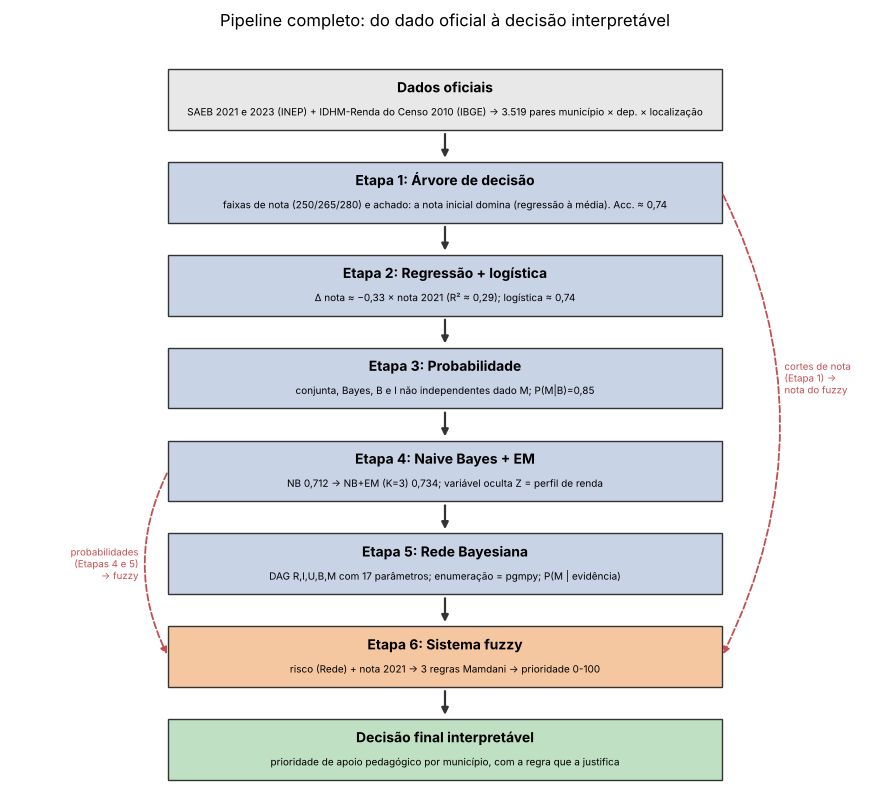

In [14]:
fig, ax = plt.subplots(figsize=(9, 8.2)); ax.axis('off'); ax.set_xlim(-1.6, 11.6); ax.set_ylim(0, 10.6)
etapas = [('Dados oficiais', 'SAEB 2021 e 2023 (INEP) + IDHM-Renda do Censo 2010 (IBGE) → 3.519 pares município × dep. × localização'),
          ('Etapa 1: Árvore de decisão', 'faixas de nota (250/265/280) e achado: a nota inicial domina (regressão à média). Acc. ≈ 0,74'),
          ('Etapa 2: Regressão + logística', 'Δ nota ≈ −0,33 × nota 2021 (R² ≈ 0,29); logística ≈ 0,74'),
          ('Etapa 3: Probabilidade', 'conjunta, Bayes, B e I não independentes dado M; P(M|B)=0,85'),
          ('Etapa 4: Naive Bayes + EM', 'NB 0,712 → NB+EM (K=3) 0,734; variável oculta Z = perfil de renda'),
          ('Etapa 5: Rede Bayesiana', 'DAG R,I,U,B,M com 17 parâmetros; enumeração = pgmpy; P(M | evidência)'),
          ('Etapa 6: Sistema fuzzy', 'risco (Rede) + nota 2021 → 3 regras Mamdani → prioridade 0-100'),
          ('Decisão final interpretável', 'prioridade de apoio pedagógico por município, com a regra que a justifica')]
ys = np.linspace(9.7, 0.7, len(etapas)); cores = ['#e8e8e8'] + ['#c9d3e6'] * 5 + ['#f4c7a1', '#bfe0c3']
for (t, s), y_, c in zip(etapas, ys, cores):
    ax.add_patch(plt.Rectangle((0.8, y_ - .42), 8.4, .84, fc=c, ec='#333', zorder=2)); ax.text(5, y_ + .17, t, ha='center', va='center', weight='bold', fontsize=10, zorder=3)
    ax.text(5, y_ - .17, s, ha='center', va='center', fontsize=7.2, zorder=3)
for y1, y2 in zip(ys[:-1], ys[1:]): ax.annotate('', xy=(5, y2 + .44), xytext=(5, y1 - .44), arrowprops=dict(arrowstyle='-|>', lw=1.6, color='#333'))
for src, dst, x_ in [(1, 6, 9.55), (4, 6, 0.45)]:        # reaproveitamentos tracejados
    ax.annotate('', xy=(9.2 if x_ > 5 else 0.8, ys[dst]), xytext=(9.2 if x_ > 5 else 0.8, ys[src]), arrowprops=dict(arrowstyle='-|>', lw=1.3, color='#c44e52', ls='--', connectionstyle='arc3,rad=-0.25' if x_ > 5 else 'arc3,rad=0.25'))
ax.text(10.15, (ys[1] + ys[5]) / 2, 'cortes de nota\n(Etapa 1) →\nnota do fuzzy', fontsize=7, color='#c44e52', ha='left', va='center')
ax.text(0.35, (ys[4] + ys[6]) / 2, 'probabilidades\n(Etapas 4 e 5)\n→ fuzzy', fontsize=7, color='#c44e52', ha='right', va='center')
ax.set_title('Pipeline completo: do dado oficial à decisão interpretável'); plt.tight_layout(); plt.show()

## 9. Discussão e resumo

| Item | Resultado |
|---|---|
| Variáveis linguísticas | `risco` (Rede, 0–1), `nota` (SAEB 2021, 230–300), `prioridade` (0–100), todas com triângulos |
| Regras | 3 regras Se-Então (operador E), lidas em linguagem de gestão |
| Implementação | scikit-fuzzy; o Mamdani manual em numpy reproduz (máx \|dif\| ≈ 0,02 em 0–100) |
| Entrada da Etapa 5 | risco = 1 − P(M=1 \| R,I,U,B), por enumeração, fora-da-amostra |
| Fronteira | grupo B=0, I=1 com risco ≈ 0,502: o hard decide por 0,002; o fuzzy varia 0,4 ponto entre 0,49 e 0,51 |
| Estabilidade (200 bootstraps) | hard: 3,7% dos municípios trocam de decisão (até 8,2%); fuzzy: variação média de 0,16 ponto, nenhum município com mais de 5 pontos |
| "Ficou baixo em 2023" (prevalência 41,5%) | hard: precisão 14% (AUC 0,18, pior que sortear) · fuzzy: 70% (AUC 0,88) · só a nota: 71% (AUC 0,88) |
| "Não melhorou" (prevalência 36,9%) | hard: 57% (AUC 0,73) · fuzzy: 16% (AUC 0,22) |

**Quando o fuzzy supera o limiar rígido?** (i) Nas **fronteiras ambíguas**: o grupo de risco ≈ 0,50 é decidido por 0,002 no hard e vira "50%" no fuzzy, e na reamostragem esse grupo cai para um lado ou outro em 55% das amostras. (ii) Com **dados ruidosos**: pequenas mudanças nas CPTs trocam a decisão de ≈ 4% dos municípios no hard, contra mudanças de décimos de ponto no fuzzy (em parte porque o risco pesa pouco na saída). (iii) Quando a decisão precisa **combinar fontes** (probabilidade da Rede + nível contínuo) de forma legível. O fuzzy **não** supera o hard quando a pergunta é exatamente a que a probabilidade foi treinada para responder (prever "não melhorou": o hard é muito melhor) e, como escore de necessidade, **empata com a nota 2021 sozinha** (AUC 0,880 contra 0,881). O ganho do fuzzy é **suavidade e interpretabilidade**, não acurácia.

**Interpretabilidade (Tarefa 7).** Cada decisão sai de três regras em linguagem natural, com graus de ativação explícitos (Seção 7). Um especialista consegue ler "nota baixa → prioridade alta" e "nota alta e risco alto → monitorar", discordar de uma regra e ajustá-la. Os pontos de corte têm origem rastreável (265 e 250/280 da Etapa 1, risco 0,5 do limiar clássico). Limites: os parâmetros dos triângulos foram escolhidos à mão (não aprendidos), a defuzzificação pelo centroide comprime a saída (36–87, não 0–100) e só há dois níveis de nota.

**Limitações para o relatório**
1. **A Rede quase não acrescenta ao nível de nota.** Risco e nota têm correlação ≈ 0,8 (regressão à média: quem partiu alto tem "risco" de não melhorar). Por isso a prioridade fuzzy é quase uma função da nota (correlação −0,93) e seu desempenho empata com o da nota sozinha. O que o pipeline entrega é uma decisão **explicável e contínua**, não uma previsão melhor.
2. **Revisões das regras.** A primeira versão (simétrica entre nota baixa e alta) deu prioridades invertidas ao conferir contra os desfechos e foi revisada pondo o nível na frente (R1), com base na regressão à média das Etapas 1–3. Depois, a regra com OU ("risco baixo OU médio") foi retirada por criar um degrau artificial na saída, e o `risco` passou a ter 2 conjuntos. Como a conferência com os desfechos influenciou o desenho, os números da Seção 6.3 têm **um pouco de otimismo**. Se o relatório exigir OU, ele pode ser usado numa regra extra, ao custo desse degrau.
3. O risco da Rede só assume 4 valores (depende de `B` e `I`), então como entrada contínua ele é pobre; a nota contínua é que traz a gradação.
4. A "prioridade de apoio" é uma recomendação de triagem, **não** uma conclusão causal; "ficou baixo em 2023" é uma proxy de necessidade, não uma medida de eficácia de qualquer política.
5. O bootstrap por município mede só o ruído de **estimação das CPTs**, não o ruído de medição do SAEB.
6. Os dados foram **reconstruídos a partir dos arquivos brutos do `Dados.zip`** (SAEB 2021, SAEB 2023, Censo 2010) com resultado idêntico ao embutido nos notebooks (3.519 linhas; diferença máxima 6e-14).


## 10. Exportar tabela para o LaTeX

In [15]:
lat = tab_c.copy(); lat['decisão'] = lat['decisão'].str.replace('%', r'\\%'); lat['desfecho'] = lat['desfecho'].str.replace('<', '$<$')
print(lat.round(3).to_latex(index=False, float_format='%.3f', caption='Etapa 6: decisão hard (limiar 0,5) e fuzzy, frente aos desfechos de 2023 (fora-da-amostra).', label='tab:etapa6'))

\begin{table}
\caption{Etapa 6: decisão hard (limiar 0,5) e fuzzy, frente aos desfechos de 2023 (fora-da-amostra).}
\label{tab:etapa6}
\begin{tabular}{llrrrr}
\toprule
desfecho & decisão & marcados & precisão & recall & AUC do escore \\
\midrule
ficou baixo em 2023 (média 2023 $<$ 265) & Hard: risco > 0,5 (Rede) & 1709 & 0.138 & 0.161 & 0.178 \\
ficou baixo em 2023 (média 2023 $<$ 265) & Fuzzy (mesma cobertura) & 1709 & 0.700 & 0.820 & 0.880 \\
ficou baixo em 2023 (média 2023 $<$ 265) & Referência: só a nota 2021 (mesma cobertura) & 1709 & 0.709 & 0.829 & 0.881 \\
não melhorou (M=0) & Hard: risco > 0,5 (Rede) & 1709 & 0.568 & 0.747 & 0.731 \\
não melhorou (M=0) & Fuzzy (mesma cobertura) & 1709 & 0.155 & 0.204 & 0.218 \\
não melhorou (M=0) & Referência: só a nota 2021 (mesma cobertura) & 1709 & 0.154 & 0.203 & 0.215 \\
\bottomrule
\end{tabular}
\end{table}

